In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import seaborn as sns
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import logging
import warnings
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.width", 200)

In [2]:
# TF1-TF2 buried surface area restricted to annotated structured domains (DNA excluded).
# Full-length BSA (notebook 0) is dominated by contacts between disordered regions, whose placement
# by AF3 is essentially arbitrary; here only curated domains count.
# Domains: data/tf_domains_structured.csv, built by scripts/fetch_tf_domains.py from UniProt
# (Domain / DNA binding / Zinc finger features) + Pfam (domain/repeat entries and folded families),
# excluding annotated transactivation/regulatory regions. Residue numbering = UniProt canonical
# (identical sequences verified). Per-model values: scripts/domain_bsa.py (sbatch scripts/domain_bsa.sbatch).
domains = pd.read_csv("../data/tf_domains_structured.csv")
domains

,TF,accession,domain,start,end
0,BCL11B,Q9C0K0,BCL-11A-like CCHC zinc finger,55,82
1,BCL11B,Q9C0K0,C2H2-type 1,221,251
2,BCL11B,Q9C0K0,"C2H2-type 2 / Zinc finger, C2H2 type / C2H2-ty...",427,482
3,BCL11B,Q9C0K0,"C2H2-type 4 / Zinc finger, C2H2 type / C2H2-ty...",796,884
4,CBFB,Q13951,Core binding factor beta subunit,1,166
5,EBF2,Q9HAK2,Transcription factor COE1 DNA-binding domain /...,17,246
6,EBF2,Q9HAK2,IPT/TIG domain / IPT/TIG / Transcription facto...,253,381
7,EBF3,Q9H4W6,Transcription factor COE1 DNA-binding domain /...,18,247
8,EBF3,Q9H4W6,IPT/TIG / IPT/TIG domain / Transcription facto...,263,391
9,ETS1,P14921,PNT / Sterile alpha motif (SAM)/Pointed domain,51,136


In [3]:
full = pd.read_csv("../results/tables/bsa_n100_rho0.6_high_vs_low.csv")
dom = pd.read_csv("../results/cache/domain_bsa_checkpoint.csv")
results = full.merge(dom, on="name", validate="1:1")
results["class"] = pd.Categorical(results["class"], categories=["high", "low"], ordered=True)
print(f"{len(results)} models ({len(full)} in full-length table)")
results.to_csv("../results/tables/domain_bsa_n100_rho0.6_high_vs_low.csv", index=False)

6400 models (6400 in full-length table)


In [4]:
# QC: annotated domains should be the ordered part of the models (mean CA pLDDT inside vs outside)
qc = pd.concat([
    results[["TF1", "plddt_dom_A", "plddt_rest_A"]].set_axis(["TF", "in_domains", "outside"], axis=1),
    results[["TF2", "plddt_dom_B", "plddt_rest_B"]].set_axis(["TF", "in_domains", "outside"], axis=1),
]).groupby("TF").mean().round(1).sort_values("in_domains")
qc

,in_domains,outside
TF,,
RELB,77.4,37.0
BCL11B,80.6,38.0
GRHL2,81.3,38.3
PKNOX2,83.2,37.7
TP73,83.4,40.3
IRF3,84.0,49.6
NFIA,84.9,36.6
NFIB,85.1,41.4
CBFB,85.1,58.9


In [5]:
# overall: domain BSA and fraction of models in which the two TFs' domains touch at all (heavy atoms <= 4 A)
summary = results.groupby("class", observed=True).agg(
    median_BSA_full=("BSA", "median"), median_BSA_domain=("BSA_domain", "median"),
    mean_BSA_domain=("BSA_domain", "mean"), frac_domains_touch=("domains_touch", "mean"))
paired = results.pivot_table(index=["group", "background_idx"], columns="class", values="BSA_domain", observed=True)
stat, p = wilcoxon(paired["high"], paired["low"])
print(f"domain BSA, paired Wilcoxon over all {len(paired)} background pairs: p = {p:.2e}")
summary.round(3)

domain BSA, paired Wilcoxon over all 3200 background pairs: p = 2.28e-29


,median_BSA_full,median_BSA_domain,mean_BSA_domain,frac_domains_touch
class,,,,
high,1116.422,373.022,363.035,0.882
low,854.931,227.362,331.874,0.711


In [6]:
# per TF-pair group: paired Wilcoxon on domain BSA (matched by background_idx), BH FDR over the 32 groups
# - same test as notebook 0 so categories are directly comparable with full-length BSA
rows = []
for grp, g in results.groupby("group"):
    hi = g[g["class"] == "high"].set_index("background_idx")
    lo = g[g["class"] == "low"].set_index("background_idx")
    common = hi.index.intersection(lo.index).sort_values()
    diff = hi.loc[common, "BSA_domain"] - lo.loc[common, "BSA_domain"]
    p = 1.0 if np.allclose(diff, 0) else wilcoxon(hi.loc[common, "BSA_domain"], lo.loc[common, "BSA_domain"])[1]
    rows.append({"group": grp, "pair": g["pair"].iloc[0], "combo": g["combo"].iloc[0], "n_pairs": len(common),
                 "mean_BSA_domain_high": hi.loc[common, "BSA_domain"].mean(),
                 "mean_BSA_domain_low": lo.loc[common, "BSA_domain"].mean(),
                 "mean_diff": diff.mean(), "n_high_gt_low": int((diff > 0).sum()), "n_low_gt_high": int((diff < 0).sum()),
                 "frac_touch_high": hi.loc[common, "domains_touch"].mean(),
                 "frac_touch_low": lo.loc[common, "domains_touch"].mean(), "wilcoxon_p": p})
pair_test = pd.DataFrame(rows)
pair_test["fdr_sig"] = multipletests(pair_test["wilcoxon_p"], alpha=0.05, method="fdr_bh")[0]
pair_test["category"] = np.where(~pair_test["fdr_sig"], "no significant difference",
                                 np.where(pair_test["mean_diff"] > 0, "high > low (good motif wins)", "low > high (REVERSE)"))

# compare with the full-length result from notebook 0
full_test = pd.read_csv("../results/tables/per_group_paired_bsa_test.csv")[["group", "mean_diff", "category"]]
pair_test = pair_test.merge(full_test.rename(columns={"mean_diff": "mean_diff_full", "category": "category_full"}), on="group")
pair_test = pair_test.sort_values("mean_diff", ascending=False).reset_index(drop=True)
pair_test.to_csv("../results/tables/per_group_paired_domain_bsa_test.csv", index=False)
pair_test.round(3)

,group,pair,combo,n_pairs,mean_BSA_domain_high,mean_BSA_domain_low,mean_diff,n_high_gt_low,n_low_gt_high,frac_touch_high,frac_touch_low,wilcoxon_p,fdr_sig,category,mean_diff_full,category_full
0,RUNX1_GABPA_14_64,RUNX1-GABPA,14_64,100,370.425,35.590,334.836,100,0,1.00,0.74,0.000,True,high > low (good motif wins),1296.359,high > low (good motif wins)
1,EBF3_NFKB2_5_17,EBF3-NFKB2,5_17,100,382.583,110.223,272.359,78,22,0.77,0.35,0.000,True,high > low (good motif wins),447.950,high > low (good motif wins)
2,SPI1_BCL11B_10_14,SPI1-BCL11B,10_14,100,287.043,25.144,261.899,97,3,0.91,0.21,0.000,True,high > low (good motif wins),440.352,high > low (good motif wins)
3,RUNX3_IKZF1_42_64,RUNX3-IKZF1,42_64,100,528.818,322.559,206.260,92,8,1.00,0.96,0.000,True,high > low (good motif wins),231.944,high > low (good motif wins)
4,RUNX3_GABPA_42_64,RUNX3-GABPA,42_64,100,229.794,24.894,204.901,97,3,0.97,0.39,0.000,True,high > low (good motif wins),1193.904,high > low (good motif wins)
5,BCL11B_ETS1_14_64,BCL11B-ETS1,14_64,100,482.225,295.214,187.011,76,24,0.97,0.87,0.000,True,high > low (good motif wins),654.483,high > low (good motif wins)
6,RUNX1_TCF7_14_157,RUNX1-TCF7,14_157,100,130.888,0.000,130.888,100,0,1.00,0.00,0.000,True,high > low (good motif wins),119.969,high > low (good motif wins)
7,RUNX1_LEF1_14_157,RUNX1-LEF1,14_157,100,125.388,0.000,125.388,100,0,1.00,0.00,0.000,True,high > low (good motif wins),245.093,high > low (good motif wins)
8,RUNX2_LEF1_14_157,RUNX2-LEF1,14_157,100,120.208,0.000,120.208,100,0,1.00,0.00,0.000,True,high > low (good motif wins),579.213,high > low (good motif wins)
9,EBF2_NFKB2_5_17,EBF2-NFKB2,5_17,100,315.941,228.328,87.613,62,36,0.81,0.65,0.012,True,high > low (good motif wins),182.117,high > low (good motif wins)


In [7]:
pd.crosstab(pair_test["category_full"], pair_test["category"], margins=True)

category,high > low (good motif wins),low > high (REVERSE),no significant difference,All
category_full,,,,
high > low (good motif wins),14,0,2,16
low > high (REVERSE),1,6,2,9
no significant difference,1,2,4,7
All,16,8,8,32


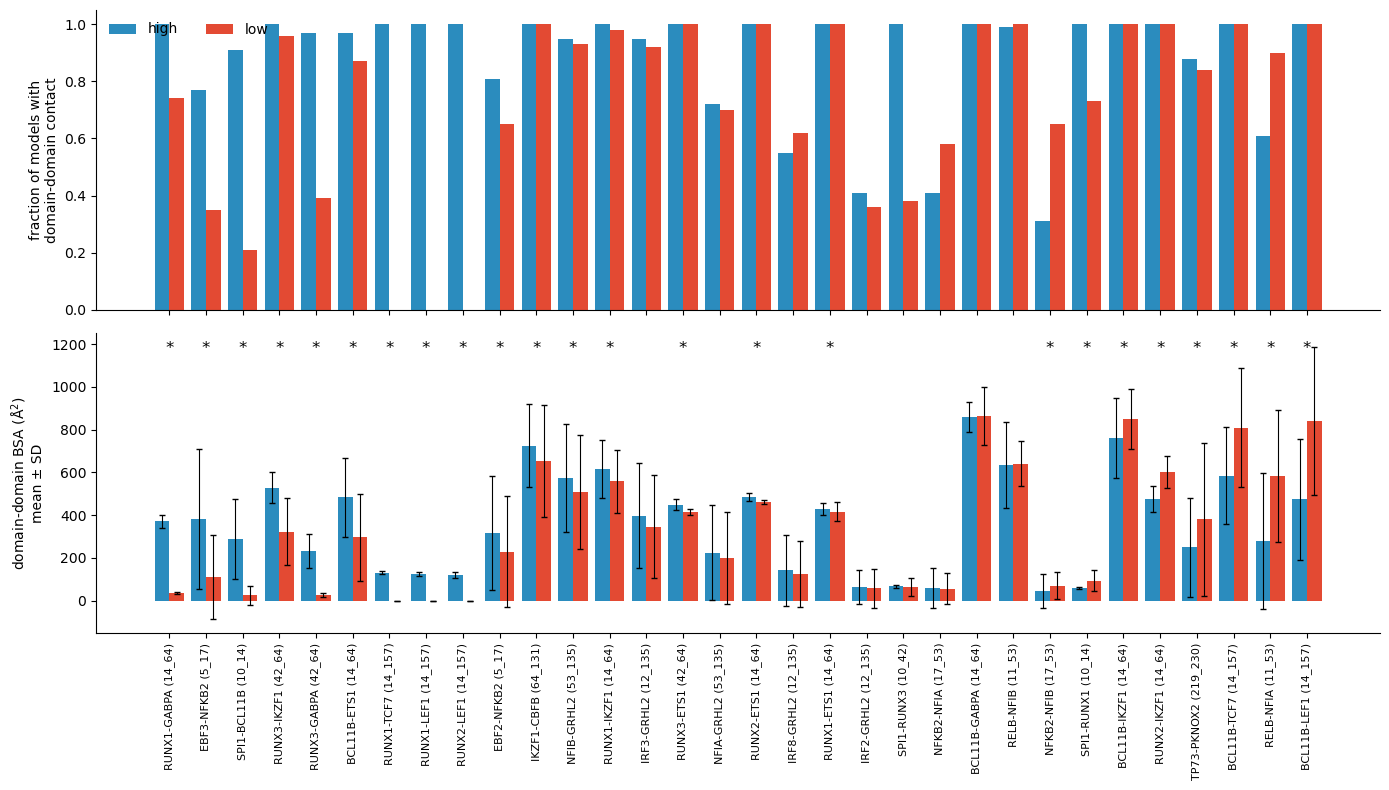

In [8]:
# figure: per TF pair, (a) fraction of models with domain-domain contact, (b) mean domain BSA, high vs low
palette = {"high": "#2b8cbe", "low": "#e34a33"}
order = pair_test.sort_values("mean_diff", ascending=False)
x = np.arange(len(order))
labels = order["pair"] + " (" + order["combo"] + ")"

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for j, cls in enumerate(["high", "low"]):
    axes[0].bar(x + (j - 0.5) * 0.4, order[f"frac_touch_{cls}"], 0.4, color=palette[cls], label=cls)
    sd = results.groupby(["group", "class"], observed=True)["BSA_domain"].std().xs(cls, level="class").reindex(order["group"])
    axes[1].bar(x + (j - 0.5) * 0.4, order[f"mean_BSA_domain_{cls}"], 0.4, yerr=sd.values, color=palette[cls],
                capsize=2, error_kw={"lw": 0.8})
for xi, (_, r) in zip(x, order.iterrows()):
    if r["fdr_sig"]:
        axes[1].text(xi, axes[1].get_ylim()[1] * 0.97, "*", ha="center", va="top", fontsize=12)
axes[0].set_ylabel("fraction of models with\ndomain-domain contact")
axes[0].set_ylim(0, 1.05)
axes[0].legend(frameon=False, ncol=2)
axes[1].set_ylabel("domain-domain BSA (Å$^2$)\nmean ± SD")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=90, fontsize=8)
sns.despine()
plt.tight_layout()
plt.savefig("../results/figures/domain_bsa_n100_rho0.6_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()

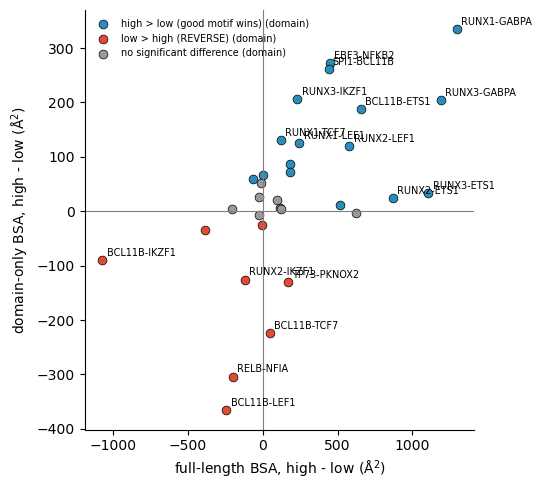

In [9]:
# full-length vs domain-only effect per TF pair (mean paired high - low difference)
fig, ax = plt.subplots(figsize=(5.5, 5))
cat_col = {"high > low (good motif wins)": "#2b8cbe", "low > high (REVERSE)": "#e34a33", "no significant difference": "0.6"}
for cat, g in pair_test.groupby("category"):
    ax.scatter(g["mean_diff_full"], g["mean_diff"], color=cat_col[cat], s=40, edgecolor="k", lw=0.5, label=f"{cat} (domain)")
for _, r in pair_test.iterrows():
    if abs(r["mean_diff"]) > 100 or abs(r["mean_diff_full"]) > 800:
        ax.annotate(r["pair"], (r["mean_diff_full"], r["mean_diff"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("full-length BSA, high - low (Å$^2$)")
ax.set_ylabel("domain-only BSA, high - low (Å$^2$)")
ax.legend(frameon=False, fontsize=7, loc="upper left")
sns.despine()
plt.tight_layout()
plt.savefig("../results/figures/domain_vs_full_bsa_diff_per_pair.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [10]:
# roll up to motif combination (as notebook 0)
per_combo = pair_test.groupby("combo").agg(
    n_tf_pairs=("group", "count"),
    n_good=("category", lambda s: (s == "high > low (good motif wins)").sum()),
    n_reverse=("category", lambda s: (s == "low > high (REVERSE)").sum()),
    n_ns=("category", lambda s: (s == "no significant difference").sum()),
).reset_index()
per_combo["has_at_least_one_good"] = per_combo["n_good"] > 0
per_combo.to_csv("../results/tables/per_combo_paired_domain_bsa_summary.csv", index=False)
per_combo

,combo,n_tf_pairs,n_good,n_reverse,n_ns,has_at_least_one_good
0,10_14,2,1,1,0,True
1,10_42,1,0,0,1,False
2,11_53,2,0,1,1,False
3,12_135,3,0,0,3,False
4,14_157,5,3,2,0,True
5,14_64,8,5,2,1,True
6,17_53,2,0,1,1,False
7,219_230,1,0,1,0,False
8,42_64,3,3,0,0,True
9,53_135,2,1,0,1,True
